# CNOT-resolved MPS zero-noise extrapolation

This notebook has **four executable cells**:

1. Define the circuit, observable and four noise models.
2. Choose the scale grid and bond budgets, then calculate MPS curves and reference values.
3. Fit ratio, direct Q, single exponential and dual exponential, with optional shot noise.
4. Inspect errors, convergence and plots, and save the results.

The default is a small **N=6, L=2** example so that exact noisy references are available. Change the first cell for larger systems. Run cells in order; after changing only shot settings, rerun cells 3–4. The fitting cell does not rerun MPS. The implementation lives in `pauli_zne/workflow.py`; returned objects retain all data. For example, inspect `calculation.curves`, `calculation.reference`, `fits.noiseless`, `fits.shot_results`, or `analysis.figure`.

**Setup:** from this package folder, install `python -m pip install -e '.[notebook]'`, then open this notebook with JupyterLab. The notebook also works directly from the source folder when the dependencies are installed.

## Circuit and noise convention

The initial state is a product of singlets on pairs (0,1), (2,3), … . A full step applies even then odd nearest-neighbor Heisenberg gates,

$$U(\phi)=\exp[-i\phi(XX+YY+ZZ)/2].$$

Each gate uses three CNOTs (right→left, left→right, right→left) and single-qubit rotations. There are **four CNOT-layer types**: `even_lr`, `even_rl`, `odd_lr`, `odd_rl`. There are six CNOT-layer occurrences per full step; the right→left types each occur twice and reuse their rates.

Each type has a global channel

$$\mathcal E_{c,s}=\exp\!\left[s\sum_P\lambda_{c,P}(P\rho P-\rho)\right].$$

We allow on-site X/Y/Z and all nine nearest-neighbor products AB. The channel acts once per CNOT layer over the entire chain, including idle sites. A Pauli path segment is damped by

$$\exp\!\left[-2s\sum_{P:\{P,Q\}=0}\lambda_{c,P}\right].$$

`before_cnot` / `after_cnot` refers to **forward state order**; backward observable evolution reverses that order. Changing placement changes the noisy circuit.

## What is calculated?

For each MPS bond cap K and noise scale s, the signed and unsigned elementary path sums are

$$S_K(s)=O_K(s)\approx\sum_i\gamma_i e^{-sD_i},\qquad
A_K(s)\approx\sum_i|\gamma_i|e^{-sD_i}.$$

The unsigned calculation takes absolute values at **each elementary gate transfer and the terminal singlet functional**, before adding paths. It is not the absolute value of the final observable.

$$R_K(s)=\frac{S_K(s)}{S_K(0)},\qquad
Q_{+,K}(s)=\frac{A_K(s)+S_K(s)}{A_K(0)+S_K(0)},\qquad
Q_{-,K}(s)=\frac{A_K(s)-S_K(s)}{A_K(0)-S_K(0)}.$$

At s=0, all defined normalized curves equal one. A vanishing denominator makes that quantity undefined; the package reports it rather than dividing by zero. Large unsigned sums are stored as logarithms.

When Q+ and Q− nearly coincide, their small difference must not be recovered by subtracting rounded displayed values. We calculate the stable contrast

$$C_K(s)=S_K(s)-\frac{A_K(s)}{A_K(0)}S_K(0),\qquad C_K(0)=0,$$

which is proportional to $Q_{\rm diff}=(Q_+-Q_-)/2$:

$$Q_{\rm diff}(s)=\frac{C_K(s)}{A_K(0)[1-(S_K(0)/A_K(0))^2]}.$$

The MPS has one physical-dimension-4 site per qubit. Its bond caps are not directly interchangeable with the earlier blocked-MPS benchmark's caps.

## Reference and fitting data

The fitting observations $y_j$ come from an independent/reference calculation of $O(s_j)$. They **do not** come from the same low-bond curves being tested. The zero-noise reference is used only to assess errors, not as a fit point.

- Small O(0): independent forward **statevector**.
- Small noisy O(s): independent **density matrix**, since noise generally creates a mixed state.
- Larger systems: an increasing MPS reference bond sweep, with per-point tolerance checks and a randomized-SVD reproducibility check. A largest available bond is not automatically called converged or exact.

## How the four fits work

All fits use the same positive-s points and **equal least-squares weights**. They use direct MPS modes, with no interpolation or polynomial approximation.

| Method | Fitted model | Zero-noise estimate |
|:--|:--|:--|
| Ratio | $y_j\approx aR_K(s_j)$ | $\widehat O(0)=a$ |
| Direct Q | $y_j\approx aQ_{\rm avg,K}(s_j)+bC_K(s_j)/C_{\max}$ | $\widehat O(0)=a$ |
| Single exponential | $y_j\approx a e^{-bs_j}$ | $\widehat O(0)=a$ |
| Dual exponential | $y_j\approx a_1e^{-b_1s_j}+a_2e^{-b_2s_j}$ | $\widehat O(0)=a_1+a_2$ |

Here $Q_{\rm avg}=(Q_++Q_-)/2$ and $C_{\max}=\max_j|C_K(s_j)|$. Rescaling changes the numerical conditioning, not the two-dimensional Q fitting model. In the exact-path limit, $O(s)$ is in that span; finite-bond truncation creates model error.

The ratio has one fitted parameter; direct Q has two. Single and dual exponentials have two and four parameters. The dual fit needs at least four points and can interpolate four observations while still extrapolating poorly. Rates and signed component amplitudes have the explicit bounds set below. Boundary hits and optimizer non-success are included in the diagnostics, not silently dropped.

For each shot scenario, only the observations are sampled:

$$\widetilde y_j=2B_j/n_j-1,\qquad B_j\sim\operatorname{Binomial}\!\left(n_j,\frac{1+y_j}{2}\right).$$

The classical ratio/Q modes stay fixed, and every method uses the same random observations. `None` means a point is kept exact; it is still an equal-weight observation, not a hard constraint. This is ordinary Pauli shot noise, not a probability-error-amplification protocol.

Errors below are normalized by $|O_{\rm ref}(0)|$. Relative errors are undefined near zero, in which case the notebook plots absolute errors.


## More complex noise models

The current backend supports **Pauli-Lindblad channels** built from any combination of on-site X/Y/Z generators and nearest-neighbor XX, XY, …, ZZ generators. Their rates can vary by qubit, bond, CNOT-layer type, and full circuit step. All rates must be **real, finite and nonnegative**.

The examples below are alternatives for the **configuration cell**, not extra computation cells. After changing the physical noise model, rerun the MPS, fitting and analysis cells. Changing shot counts alone still requires only fitting and analysis.

### Defaults and channel overrides

`noise["single"]` and `noise["pair"]` supply shared defaults. A named channel's `"single"` or `"pair"` **replaces that entire field for that channel**; it is not added to the default. An omitted field inherits the default. For example, overriding `"single"` alone leaves the default pair noise in place.

Channel order for arrays is **even_lr, even_rl, odd_lr, odd_rl**. The same model is reused for repeated occurrences of a type within a full step. Every selected channel acts globally, once per matching CNOT layer; these arrays do not automatically restrict noise to the active CNOT bonds.

### Example: sampled site disorder plus correlated pair noise

This samples independent on-site rates for each channel and qubit, then adds selected pair generators. Sampling happens **once**, with a fixed seed. All s points use the same sampled arrays; s multiplies the rates. Do not resample the physical model at each s or in each measurement-shot trial.

```python
import numpy as np
from pauli_zne.workflow import define_experiment

N, L = 6, 2
rng = np.random.default_rng(7)
channel = {"even_lr": 0, "even_rl": 1, "odd_lr": 2, "odd_rl": 3}

# Axes: [channel, qubit, X/Y/Z].
mean = np.array([0.001, 0.001, 0.0001])
single = np.maximum(
    rng.normal(mean, 0.10 * mean, size=(4, N, 3)),
    0.0,  # Gaussian draws are clipped to preserve nonnegative rates.
)

# Axes: [channel, bond-left-qubit, left X/Y/Z, right X/Y/Z].
pair = np.zeros((4, N - 1, 3, 3))
pair[:, :, 2, 2] = 0.0002                    # ZZ noise on every adjacent pair
pair[channel["odd_rl"], 1, 0, 1] = 0.00005    # X_1 Y_2, only in odd_rl

# Optional: sample every pair-generator rate independently instead.
# pair = np.maximum(rng.normal(0.0001, 0.00001, (4, N-1, 3, 3)), 0.0)

experiment = define_experiment(
    N=N, L=L, phi=np.pi / 16, O=None,  # centered ZZ observable
    noise={
        "placement": "before_cnot",  # or "after_cnot"
        "single": single.tolist(),
        "pair": pair.tolist(),
        "channels": {},              # no overrides replacing these samples
    },
)
```

`pair[c,q,a,b]` is the rate of the dissipator generated by $\sigma_a^{(q)}\sigma_b^{(q+1)}$. Thus the nonzero XY entry above describes **correlated Pauli noise**, not a coherent XY gate. The 3×3 array is a table of nine generator rates, not a covariance matrix: XY and YX are different generators, and the table need not be symmetric.

Clipping a Gaussian changes its distribution near zero. A positive distribution such as a lognormal is another choice; an untruncated Gaussian can produce invalid negative rates.

### Array shapes and step-dependent noise

| Scope | `single` shape | `pair` shape |
|:--|:--|:--|
| Same spatial model for every channel and step | `(N,3)` | `(N-1,3,3)` |
| Different model for each channel type | `(4,N,3)` | `(4,N-1,3,3)` |
| Also different for each full circuit step | `(L,4,N,3)` | `(L,4,N-1,3,3)` |

A scalar broadcasts to every rate in its field. A single `[lambda_X,lambda_Y,lambda_Z]` vector broadcasts to all qubits and channels. For a **named channel override**, omit the channel axis: use `(N,3)` or `(L,N,3)` for singles and `(N-1,3,3)` or `(L,N-1,3,3)` for pairs.

For example, starting with the sampled arrays above, make the noise grow by 5% per full forward circuit step:

```python
step_multiplier = 1.0 + 0.05 * np.arange(L)
single_by_step = single[None, ...] * step_multiplier[:, None, None, None]
pair_by_step = pair[None, ...] * step_multiplier[:, None, None, None, None]

experiment = define_experiment(
    N=N, L=L, phi=np.pi / 16, O=None,
    noise={
        "single": single_by_step.tolist(),
        "pair": pair_by_step.tolist(),
        "channels": {},
    },
)
```

Step 0 is the first full step in forward state evolution. The same step-dependent schedule is held fixed across the s grid. This interface does not separately parameterize the two occurrences of the same CNOT-layer type within one step.

### Load calibrated or pre-sampled rates from a file

Save arrays with the same shapes under the keys `single_rates` and `pair_rates`:

```python
np.savez("noise_rates.npz", single_rates=single_by_step, pair_rates=pair_by_step)
experiment = define_experiment(
    N=N, L=L, phi=np.pi / 16, O=None,
    noise={"rates_file": "noise_rates.npz", "channels": {}},
    rates_directory=".",
)
```

With the Python API, `rates_directory` specifies the base directory for noise files; it defaults to the working directory. JSON configurations resolve paths relative to the configuration file. A whole-model NPZ replaces the shared defaults, and any named channel overrides are applied afterward. A named channel can instead use `{"file": "odd_rl_rates.npz"}` containing just its two rate arrays, without the channel axis. Each exported run saves the fully resolved arrays in `inputs.npz`.

### Channels that need a backend extension

Arbitrary Kraus channels, amplitude damping, coherent over-rotations, non-nearest-neighbor/multi-qubit generators, and cross terms between different Lindblad generators are **not supported by these rate fields**. They cannot be added by supplying complex-valued or negative lambda entries. They require extending both the MPS propagation and the independent reference calculation; the unsigned path/Q definition must also be reviewed for that extension.


## 1 · Define the circuit, observable and noise model

Edit the arguments below. Each channel accepts scalar rates or site-dependent X/Y/Z arrays, plus optional nearest-neighbor pair rates. Full noise schedules and NPZ files use the same schema as the package configuration. `O=None` chooses a centered ZZ observable for the selected N.

In [1]:
from math import pi
from pauli_zne.workflow import (
    define_experiment, calculate_curves, fit_curves, analyze_results,
)

experiment = define_experiment(
    N=6, L=2, phi=pi / 16, O="IIZIZI",
    noise={
        "placement": "before_cnot",  # or "after_cnot" in forward state order
        "single": [0.001, 0.001, 0.0001],
        "pair": 0.0,
        "channels": {
            "even_lr": {"single": [0.0010, 0.0015, 0.0001]},
            "even_rl": {"single": [0.0012, 0.0010, 0.0001]},
            "odd_lr":  {"single": [0.0008, 0.0010, 0.0001]},
            "odd_rl":  {"single": [0.0010, 0.0010, 0.0003]},
        },
    },
)

## 2 · Calculate MPS curves on the selected grid

This is the expensive cell. It builds the signed and unsigned channels at each requested K, derives R and the Q modes, then obtains independent/reference O(s) values. Cached signed contractions can be reused by the reference sweep. No fitting occurs here.

In [2]:
calculation = calculate_curves(
    experiment,
    s_grid=[1, 2, 4, 8],
    bond_dims=[16, 32, 64],
    reference_bonds=[128, 256, 512],
)

Completed signed/unsigned MPS curves at K=16
Completed signed/unsigned MPS curves at K=32
Completed signed/unsigned MPS curves at K=64
Exact density reference s=0
Exact density reference s=1


Exact density reference s=2
Exact density reference s=4
Exact density reference s=8
O(0)=0.00780949136861 (statevector); noisy reference=density_matrix; converged=True
Captured numerical warnings: inspect alongside reference/convergence checks.


,category,message,count
0,RuntimeWarning,divide by zero encountered in dot,2304
1,RuntimeWarning,overflow encountered in dot,2304
2,RuntimeWarning,invalid value encountered in dot,2304
3,RuntimeWarning,divide by zero encountered in matmul,420
4,RuntimeWarning,overflow encountered in matmul,420
5,RuntimeWarning,invalid value encountered in matmul,420


,s,O_reference(s)
0,0.0,0.007809
1,1.0,0.005221
2,2.0,0.003088
3,4.0,-0.000075
4,8.0,-0.003348


## 3 · Run each fitting method

The noisy-data means are the reference curve from cell 2. Change `shots` or `trials` here and rerun cells 3–4 without repeating MPS. Use `shots={}` for noiseless fits only. Optional `observations=[...]` supplies hardware means in positive-s order; the comparison target remains the simulation reference. Rate and amplitude bounds can also be passed here.

In [3]:
fits = fit_curves(
    calculation,
    trials=200, seed=7,
    shots={
        "100k_each": 100_000,
        "1m_each": 1_000_000,
        "10m_each": 10_000_000,
        "exact_tail": {"1": 100_000, "2": 1_000_000, "4": None, "8": None},
    },
)

Finished shot scenario 100k_each: 200 paired trials


Finished shot scenario 1m_each: 200 paired trials


Finished shot scenario 10m_each: 200 paired trials


Finished shot scenario exact_tail: 200 paired trials


,method,status,estimate,relative_error_pct,sse
0,ratio_K16,ok,0.007781,-3.642854e-01,6.080225e-08
1,Q_K16,ok,0.007806,-4.501226e-02,6.611751e-11
2,ratio_K32,ok,0.007812,2.590010e-02,1.140843e-10
3,Q_K32,ok,0.007812,3.434958e-02,2.667388e-12
4,ratio_K64,ok,0.007809,-3.817196e-10,1.287095e-27
5,Q_K64,ok,0.007809,-3.968466e-10,9.161597e-28
6,single_exp,ok,0.011820,5.134830e+01,1.212276e-05
7,dual_exp,ok,0.007809,3.992567e-05,1.576350e-30


## 4 · Analyze, plot and save

Read the raw observable and normalized-mode convergence alongside the intercept errors. A tiny residual at the fitted points does not certify extrapolation accuracy. The shot-noise panel compares all scenarios for the largest requested classical bond; per-bond results remain in the tables. Exponential lines between points are the fitted models; Q/ratio points are connected only as visual guides, not interpolated during fitting.

,K,s,O error / |O_ref(0)| (%),R_K minus R_reference
0,16,0.0,-3.479474e+00,-1.065814e-14
1,16,1.0,-2.924872e+00,-6.201597e-03
2,16,2.0,-2.428369e+00,-1.090660e-02
3,16,4.0,-1.601502e+00,-1.693916e-02
4,16,8.0,-7.988171e-01,-2.372998e-02
5,32,0.0,-1.628548e-01,-1.065814e-14
6,32,1.0,-1.472574e-01,-3.843927e-04
7,32,2.0,-1.326272e-01,-6.835154e-04
8,32,4.0,-8.632979e-02,-8.803993e-04
9,32,8.0,-3.095818e-03,-7.302888e-04


,scenario,shots @ s=1,shots @ s=2,shots @ s=4,shots @ s=8
0,100k_each,100000,100000,100000.0,100000.0
1,1m_each,1000000,1000000,1000000.0,1000000.0
2,10m_each,10000000,10000000,10000000.0,10000000.0
3,exact_tail,100000,1000000,exact,exact


method,ratio_K64,Q_K64,single_exp,dual_exp
scenario,,,,
100k_each,45.926289,45.971877,3887.283630,3607.313198
1m_each,15.710008,15.739410,86.710856,444.898510
10m_each,3.902894,3.923456,55.428617,7.826643
exact_tail,35.170687,35.791701,704.113930,1862.590708


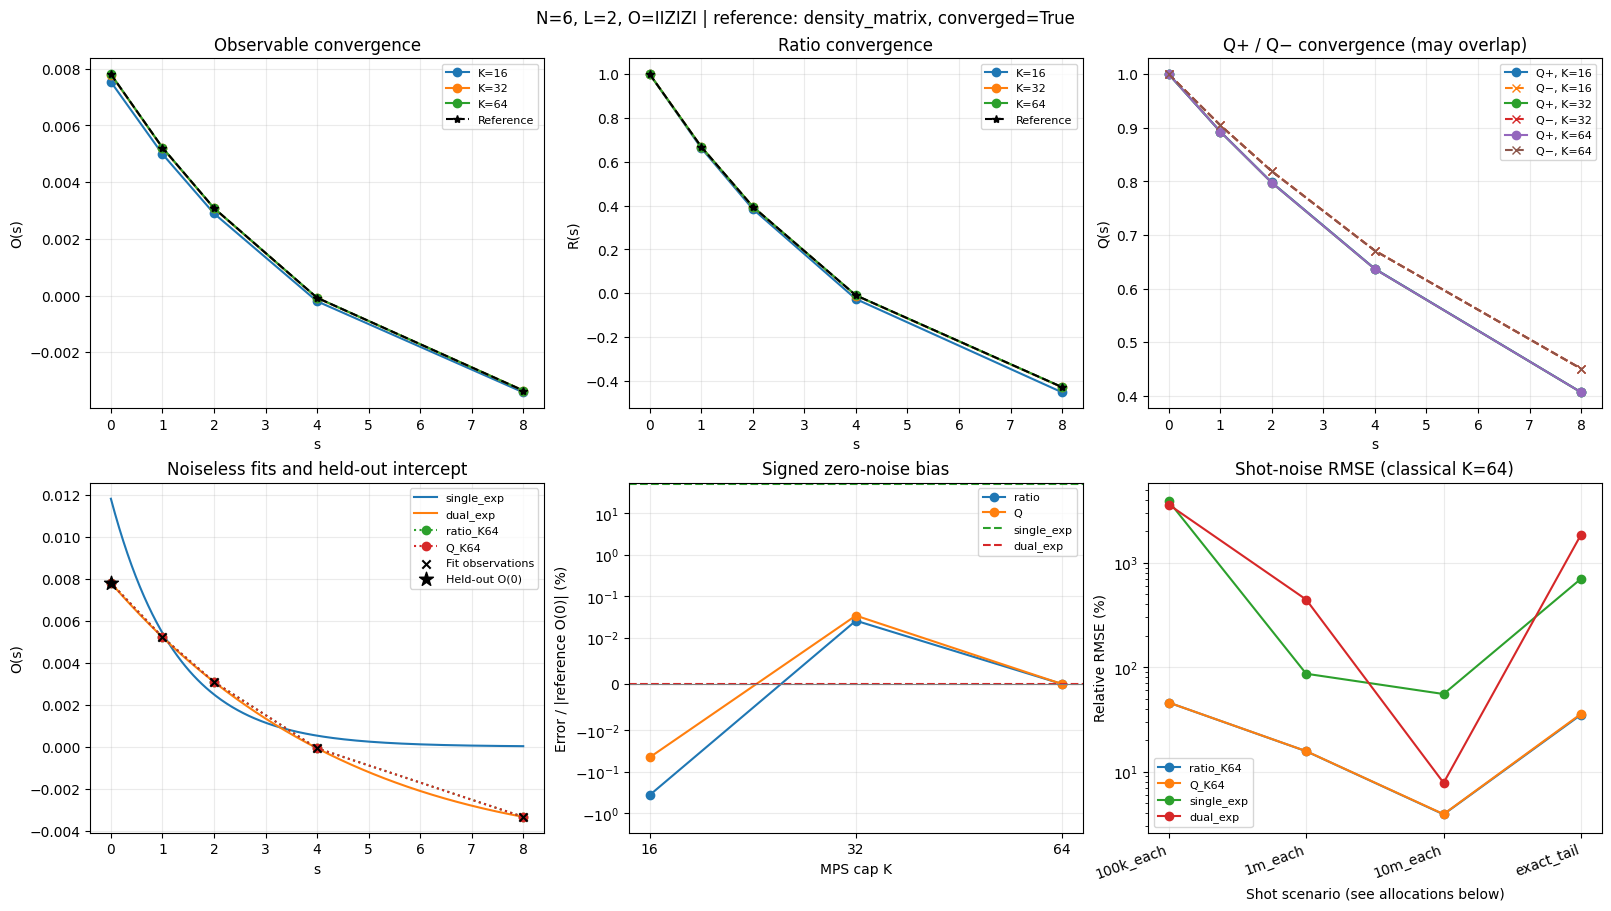

Saved: runs/notebook_20261002T145627_811725Z
Finite-bond reference checks are empirical, not rigorous error bounds.


In [4]:
analysis = analyze_results(fits, save=True, output_root="runs")